In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as seabornInstance 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics 

In [3]:
# Wczytanie danych z pliku CSV (oddzielonych średnikiem)
dataset = pd.read_csv('Kruk_VLagun_156.csv', sep=';')

In [4]:
print("Wymiary danych:", dataset.shape)

Wymiary danych: (156, 30)


In [5]:
print("Podsumowanie statystyczne:", dataset.describe())

Podsumowanie statystyczne:         SecchDisc          SS          TP        NH4N        NO3N         DIN  \
count  156.000000  156.000000  156.000000  156.000000  156.000000  156.000000   
mean     0.376026   86.937115  172.003205    0.029429    0.037071    0.066500   
std      0.115147   35.506823   51.697205    0.017682    0.020047    0.026033   
min      0.200000   29.000000   61.300000    0.002000    0.007000    0.024000   
25%      0.300000   60.000000  133.050000    0.019000    0.024000    0.049750   
50%      0.350000   80.000000  168.650000    0.026000    0.032000    0.061000   
75%      0.450000  111.562500  206.800000    0.035000    0.044250    0.075250   
max      0.700000  217.500000  327.600000    0.106000    0.142000    0.157000   

              DON       TN/TP          Fe  DiatomsBiomassC  
count  156.000000  156.000000  156.000000       156.000000  
mean     0.573897    8.578482    0.032126         0.112115  
std      0.173958    2.502310    0.020846         0.118436  

In [ ]:
# Zamiana formatu kolumn na liczby (coerce zamienia błędy, np. "18.mar", na wartości puste NaN)
dataset['SS'] = pd.to_numeric(dataset['SS'], errors='coerce')
dataset['SecchDisc'] = pd.to_numeric(dataset['SecchDisc'], errors='coerce')

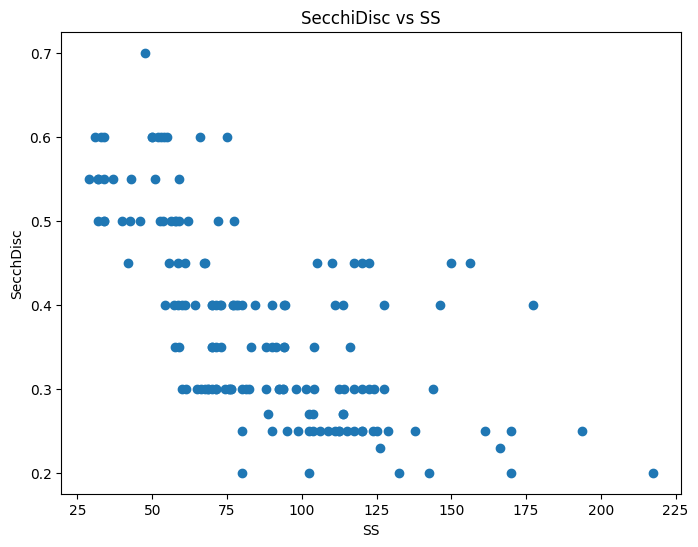

In [6]:
# --- WIZUALIZACJA DANYCH ---

# 1. Wykreślenie punktów danych na wykresie 2D (wykres rozrzutu)
x1 = dataset['SS']
y1 = dataset['SecchDisc']
plt.figure(figsize=(8,6))
plt.scatter(x1, y1) # Tworzy chmurę punktów
plt.title('SecchiDisc vs SS')
plt.xlabel('SS') # Oś X: Zawiesina
plt.ylabel('SecchDisc') # Oś Y: Widzialność krążka
plt.show()

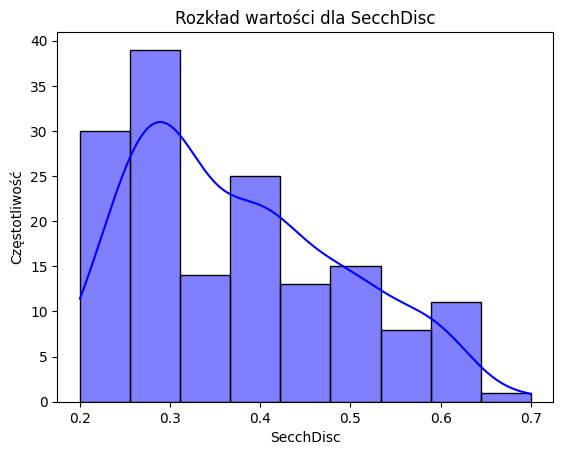

In [7]:
# 2. Rysowanie wykresu rozkładu (histogramu) dla widzialności
plt.figure()
seabornInstance.histplot(dataset['SecchDisc'], kde=True, color='blue') # kde=True dodaje krzywą gęstości
plt.title('Rozkład wartości dla SecchDisc')
plt.xlabel('SecchDisc')
plt.ylabel('Częstotliwość')
plt.show()

In [8]:
# --- PRZYGOTOWANIE DO UCZENIA MASZYNOWEGO ---

# Definicja atrybutów (X) i etykiet (y). 
# reshape(-1,1) jest konieczne, by przekształcić jednowymiarową listę w tablicę 2D (wymóg scikit-learn)
X = dataset['SS'].values.reshape(-1,1)
y = dataset['SecchDisc'].values.reshape(-1,1)

# Podział danych na zbiór do uczenia (80%) i do testowania (20%)
# random_state=0 zapewnia, że przy każdym uruchomieniu podział będzie taki sam
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# Utworzenie modelu Regresji Liniowej
regressor = LinearRegression()

# Uczenie modelu na danych treningowych (dopasowywanie linii do punktów)
regressor.fit(X_train, y_train)

# Wyświetlenie matematycznych parametrów narysowanej linii (y = ax + b)
print("Wartość przechwycenia (punkt przecięcia z osią Y, 'b'):")
print(regressor.intercept_)
print("\n")
print("Wartość nachylenia (współczynnik 'a'):")
print(regressor.coef_)

Wartość przechwycenia (punkt przecięcia z osią Y, 'b'):
[0.55338577]


Wartość nachylenia (współczynnik 'a'):
[[-0.00201303]]


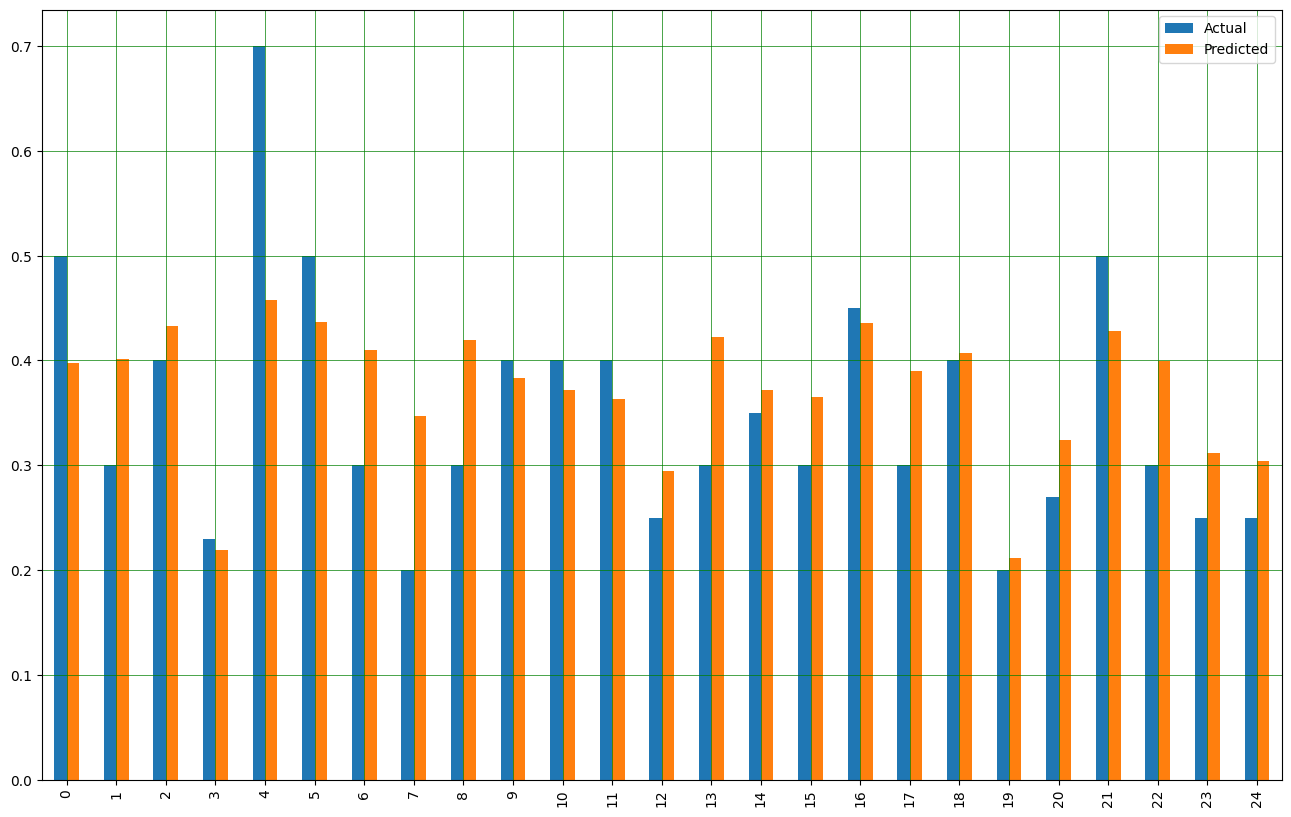

In [10]:
# --- TESTOWANIE I EWALUACJA MODELU ---

# Model próbuje przewidzieć widzialność (y) na podstawie testowych wartości zawiesiny (X_test)
y_pred = regressor.predict(X_test)

# Stworzenie tabeli porównującej to, co było w rzeczywistości, z tym co przewidział model
df = pd.DataFrame({'Actual': y_test.flatten(), 'Predicted': y_pred.flatten()})
# Rysowanie wykresu słupkowego dla pierwszych 25 przewidywań (Rzeczywiste vs Przewidywane)
df1 = df.head(25)
df1.plot(kind='bar',figsize=(16,10))
plt.grid(which='major', linestyle='-', linewidth='0.5', color='green')
plt.grid(which='minor', linestyle=':', linewidth='0.5', color='black')
plt.show()

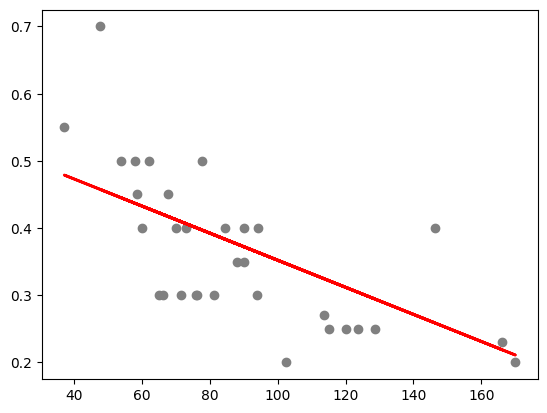

In [11]:
# Rysowanie ostatecznego wykresu z czerwoną linią trendu nałożoną na rzeczywiste punkty testowe
plt.scatter(X_test, y_test,  color='gray') # Prawdziwe punkty na szaro
plt.plot(X_test, y_pred, color='red', linewidth=2) # Linia przewidywań modelu na czerwono
plt.show()

In [12]:

# --- OBLICZANIE BŁĘDÓW ---

# Wypisanie metryk świadczących o jakości modelu
print('Mean Absolute Error (Średni błąd bezwzględny):', metrics.mean_absolute_error(y_test, y_pred))
print('Mean Squared Error (Błąd średniokwadratowy):', metrics.mean_squared_error(y_test, y_pred))
print('Root Mean Squared Error (Pierwiastek błędu średniokwadratowego):', np.sqrt(metrics.mean_squared_error(y_test, y_pred)))


Mean Absolute Error (Średni błąd bezwzględny): 0.06680798903466384
Mean Squared Error (Błąd średniokwadratowy): 0.00702853326805623
Root Mean Squared Error (Pierwiastek błędu średniokwadratowego): 0.08383634813167991
